# 🎓 Comprendre le Machine Learning & Notre Modèle de Scoring de A à Z
### *Guide Pédagogique et Littéral — De la Théorie Mathématique à la Réalité Bancaire Ivoirienne*
**Auteur :** Antigravity & Équipe Projet UIYA Microfinance  
**Public cible :** Toute personne désirant comprendre concrètement le Machine Learning, sans jargon complexe, avec des métaphores du quotidien et des exemples réels.

---

## 🌟 Avant-propos : Pourquoi ce carnet existe-t-il ?
Dans le monde de la programmation classique, si vous voulez qu'un ordinateur prenne une décision, vous devez lui écrire toutes les règles une par une avec des `SI ... ALORS ... SINON` :
- *Exemple :* `SI le client gagne plus de 100 000 FCFA ALORS accorder le prêt, SINON refuser.`

**Mais dans la vraie vie, ce système est aveugle :**
- Que fait-on pour une vendeuse de pagnes au marché d'Adjamé qui gagne 80 000 FCFA mais n'a **jamais eu un seul jour de retard** sur ses factures d'électricité depuis 10 ans ?
- Que fait-on pour un fonctionnaire qui gagne 400 000 FCFA mais qui est surendetté jusqu'au cou et dilapide tout son argent ?

C'est là qu'intervient le **Machine Learning (l'Apprentissage Automatique)**.  
Au lieu de dicter des règles rigides à l'ordinateur, **on lui donne 6 000 dossiers de clients passés** (avec leurs réussites et leurs impayés), et **on le laisse découvrir lui-même les indices cachés** qui distinguent une personne solvable d'un mauvais payeur.

---

## 🗺️ Le Sommaire de notre Voyage :
1. **L'Intuition du Détective :** Comment pense une Machine ?
2. **Le Défi de la Microfinance :** Pourquoi les données classiques ne suffisent pas en Afrique ?
3. **Exploration du Dataset :** Les 11 indices que nous confions à l'IA.
4. **Le Grand Piège :** L'illusion de l'élève paresseux (le déséquilibre des classes).
5. **La Traduction pour l'Ordinateur :** One-Hot Encoding et Mise à l'échelle.
6. **L'Examen Blanc :** L'art de tester son IA sans tricher (Train / Test Split).
7. **La Balance à Plateaux :** Comment fonctionne la Régression Logistique Équilibrée.
8. **La Métrique Finale :** De la probabilité de défaut à la note sur 1 000.
9. **Trois Cas Pratiques en Direct :** Aminata, Koffi et Ibrahim face à l'IA.
10. **Le Lexique Humain :** Les 10 mots clés à maîtriser pour briller en soutenance.

---
## 1. Le Défi de la Microfinance en Côte d'Ivoire : Pourquoi l'IA ?

Dans une grande banque européenne ou américaine, pour avoir un crédit, c'est simple : vous présentez vos 3 derniers bulletins de salaire, votre contrat CDI et un historique bancaire officiel.

**En Côte d'Ivoire, plus de 70% de la population active travaille dans le secteur informel :**
- Artisans, couturières, transporteurs de gbaka, commerçantes de vivriers, petits planteurs.
- Ils n'ont **aucun bulletin de salaire**.
- Ils n'ont souvent **aucun compte bancaire classique**.

Pourtant, ces personnes travaillent dur, gagnent de l'argent et remboursent leurs dettes avec honneur !

### 💡 L'idée maîtresse de notre projet : Les « Données Alternatives »
Puisque le client n'a pas de fiche de paie officielle, nous observons ses **traces numériques du quotidien** :
1. **Son compte Mobile Money (Orange, Wave, MTN, Moov) :**
   - Depuis combien de mois l'utilise-t-il ? (Preuve de stabilité)
   - Quel volume d'argent y fait-il transiter chaque mois ? (Preuve de chiffre d'affaires réel)
2. **Ses factures de commodités (CIE pour l'électricité, SODECI pour l'eau) :**
   - Est-ce qu'il paie ses factures à l'heure chaque fin de mois ? (Preuve de rigueur morale et budgétaire)
3. **Son historique de crédit communautaire :**
   - A-t-il déjà pris de petits crédits antérieurs qu'il a scrupuleusement remboursés ?

Ce sont ces données que nous allons fournir à notre modèle d'Intelligence Artificielle.

---
## 2. Découverte de nos Données : 6 000 Dossiers Historiques

Commençons par importer nos outils Python et charger le fichier de données réelles de notre projet : `19_finance_credit_microfinance.csv`.

In [1]:
# Importation des bibliothèques fondamentales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'affichage graphique
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)

# Chargement du fichier CSV
df = pd.read_csv('19_finance_credit_microfinance.csv')

print(f"✅ Dataset chargé avec succès !")
print(f"📊 Nombre total de dossiers analysés : {df.shape[0]} personnes")
print(f"📋 Nombre d'informations par personne : {df.shape[1]} colonnes")

# Affichage des 5 premières lignes
df.head()

✅ Dataset chargé avec succès !
📊 Nombre total de dossiers analysés : 6000 personnes
📋 Nombre d'informations par personne : 13 colonnes


,client_id,age,sexe,ville,activite,revenu_mensuel_estime_fcfa,anciennete_mobile_money_mois,volume_mm_mensuel_fcfa,factures_cie_sodeci_payees_pct,nb_credits_anterieurs,montant_demande_fcfa,duree_mois,defaut
0,1,39,F,Man,agriculture,140000.0,89,45000.0,0.84,1,220000.0,3,0
1,2,31,M,Korhogo,salarie,199000.0,5,206000.0,0.64,2,650000.0,9,0
2,3,36,M,Korhogo,salarie,153000.0,74,439000.0,0.80,1,110000.0,24,0
3,4,48,F,Divo,salarie,125000.0,103,190000.0,0.77,1,80000.0,6,0
4,5,54,F,Korhogo,agriculture,188000.0,83,282000.0,0.79,1,310000.0,3,0


### 🔍 Décortiquons chaque colonne comme un détective :

1. **`client_id`** : L'identifiant anonyme du dossier (aucun pouvoir prédictif, c'est juste un matricule).
2. **`age`** : L'âge du demandeur (en années).
3. **`sexe`** : `F` (Femme) ou `M` (Homme).
4. **`ville`** : Ville d'activité en Côte d'Ivoire (Abidjan, Yamoussoukro, Bouaké, San-Pédro, Korhogo, etc.).
5. **`activite`** : Secteur professionnel (Commerce, Artisanat, Transport, Couture, Salarié, etc.).
6. **`revenu_mensuel_estime_fcfa`** : L'estimation des revenus réguliers déclarés par le client.
7. **`anciennete_mobile_money_mois`** : Nombre de mois d'ancienneté sur son compte Mobile Money.
8. **`volume_mm_mensuel_fcfa`** : Somme moyenne qui circule sur son compte Mobile Money chaque mois.
9. **`factures_cie_sodeci_payees_pct`** : Pourcentage de factures d'eau/électricité réglées à bonne date (de 0.0 = 0% à 1.0 = 100%).
10. **`nb_credits_anterieurs`** : Nombre de prêts déjà contractés et remboursés avec succès dans le passé.
11. **`montant_demande_fcfa`** : La somme que le client sollicite aujourd'hui auprès de la microfinance.
12. **`duree_mois`** : En combien de mois le client s'engage-t-il à rembourser.
13. **`defaut` (LA CIBLE / LE TARGET) :**
    - **`0`** : Le client **a bien remboursé** son prêt jusqu'au bout sans incident majeur.
    - **`1`** : Le client **a fait défaut** (impayé grave, refus de remboursement, disparition).

---
## 3. Le Grand Piège du Débutant : Le Déséquilibre des Classes

Regardons comment se répartissent les bons et les mauvais payeurs dans notre base de données.

🟢 Bons payeurs (0 - Remboursé) : 4778 dossiers (79.63 %)
🔴 Défauts de paiement (1 - Impayé) : 1222 dossiers (20.37 %)


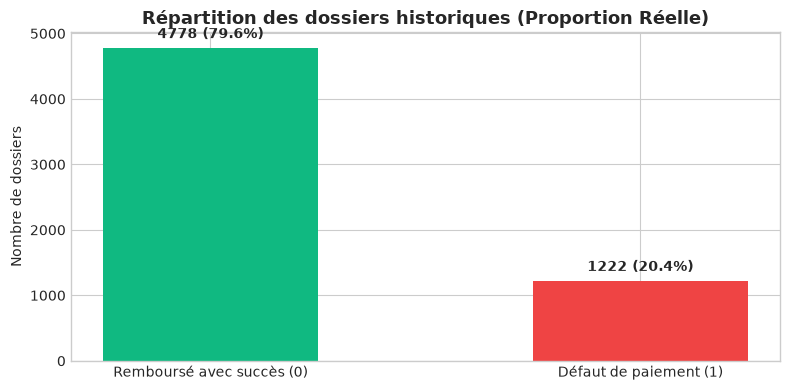

In [2]:
# Comptons le nombre de bons payeurs (0) et de mauvais payeurs (1)
repartition = df['defaut'].value_counts()
pourcentages = df['defaut'].value_counts(normalize=True) * 100

print(f"🟢 Bons payeurs (0 - Remboursé) : {repartition[0]} dossiers ({pourcentages[0]:.2f} %)")
print(f"🔴 Défauts de paiement (1 - Impayé) : {repartition[1]} dossiers ({pourcentages[1]:.2f} %)")

# Visualisons cette réalité sous forme de graphique clair
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(['Remboursé avec succès (0)', 'Défaut de paiement (1)'], repartition, color=['#10B981', '#EF4444'], width=0.5)
ax.set_title("Répartition des dossiers historiques (Proportion Réelle)", fontsize=13, fontweight='bold')
ax.set_ylabel("Nombre de dossiers")

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    ax.text(bar.get_x() + bar.get_width()/2, yval + 100, f"{yval} ({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### ⚠️ L'histoire de l'élève paresseux (L'illusion de l'Accuracy)

Regardez attentivement le graphique ci-dessus :  
**80 % des clients remboursent, et seulement 20 % font défaut.**

Imaginons maintenant un élève très paresseux qui passe un examen sous forme de QCM (Vrai / Faux).  
Si 80 % des réponses de l'examen sont « Vrai » :
- L'élève paresseux décide de répondre systématiquement **« Vrai » à toutes les questions sans même lire le sujet**.
- Résultat de l'examen : l'élève obtient **80 % de bonnes réponses (80/100)** !
- Est-il intelligent ? Sait-il reconnaître un piège ? **Non, absolument pas !**

**En Machine Learning bancaire, c'est exactement le même danger :**
Si une IA dit bêtement à tout le monde : *"Oui, accordez le prêt à 100% des gens"*, elle aura 80% de précision !  
Mais la banque va faire faillite, car les 20% de voleurs ou d'impayés n'auront jamais été détectés !

👉 **C'est pour cela que nous utilisons une Régression Logistique avec `class_weight='balanced'` :**  
Nous disons à l'ordinateur : *"Chaque fois que tu rates un mauvais payeur (1), la punition est 4 fois plus sévère que si tu te trompes sur un bon payeur !"* De cette façon, l'IA est obligée d'ouvrir l'œil et de traquer le moindre indice de risque.

---
## 4. Préparer les Données pour l'Ordinateur : La Phase de Traduction

Un algorithme de Machine Learning est une machine purement mathématique.  
Il ne sait pas ce que signifie le mot *"Yamoussoukro"* ou le mot *"Commerce"*. Il ne peut faire des calculs que sur des **nombres réels**.

Nous devons donc faire deux choses fondamentales :
1. **L'ingénierie des variables (Feature Engineering) :** Créer un ratio financier clé.
2. **Le One-Hot Encoding (L'encodage binaire) :** Transformer le texte en colonnes de cases à cocher `0` ou `1`.
3. **Le StandardScaler (La mise à l'échelle) :** Mettre toutes les grandeurs à la même dimension pour qu'un revenu de 300 000 FCFA n'écrase pas un âge de 35 ans.

In [3]:
# 1. Feature Engineering : Le Taux d'Effort (Ratio d'endettement estimé)
# En banque, un des meilleurs indicateurs est : Mensualité / Revenu mensuel
# Mensualité = Montant demandé / Durée en mois
mensualite_theorique = df['montant_demande_fcfa'] / df['duree_mois']
df['ratio_endettement'] = mensualite_theorique / df['revenu_mensuel_estime_fcfa'].replace(0, 1)

print("Exemple de ratio d'endettement calculé pour les 3 premiers clients :")
print(df[['montant_demande_fcfa', 'duree_mois', 'revenu_mensuel_estime_fcfa', 'ratio_endettement']].head(3))

Exemple de ratio d'endettement calculé pour les 3 premiers clients :
   montant_demande_fcfa  duree_mois  revenu_mensuel_estime_fcfa  \
0              220000.0           3                    140000.0   
1              650000.0           9                    199000.0   
2              110000.0          24                    153000.0   

   ratio_endettement  
0           0.523810  
1           0.362926  
2           0.029956  


### 📦 Le One-Hot Encoding expliqué simplement

Imaginons la colonne `sexe` (`F` ou `M`) et la colonne `activite` (`commerce`, `transport`, `artisanat`).  
L'ordinateur va remplacer ces colonnes par des cases à cocher :

| Client | Sexe_F | Sexe_M | Activite_Commerce | Activite_Transport | Activite_Artisanat |
| :---: | :---: | :---: | :---: | :---: | :---: |
| Aminata (Commerçante) | **1** | 0 | **1** | 0 | 0 |
| Koffi (Chauffeur) | 0 | **1** | 0 | **1** | 0 |

Tout devient mathématique, limpide et sans ambiguïté !

---
## 5. L'Examen Blanc : Séparation Entraînement (80%) et Test (20%)

Pour savoir si un étudiant a vraiment compris ses cours, le professeur ne lui donne **jamais à l'examen les mêmes exercices corrigés qu'il a vus en classe**.  
Sinon, l'étudiant pourrait simplement apprendre les réponses par cœur (c'est ce qu'on appelle le **Surapprentissage / Overfitting** en IA).

En Machine Learning, on coupe notre fichier en deux parties indépendantes :
- **Le jeu d'entraînement (Train - 80%) :** C'est le livre de révision. L'IA regarde les dossiers ET regarde si la personne a remboursé ou pas pour apprendre les patterns.
- **Le jeu de test (Test - 20%) :** C'est l'examen final. On donne les dossiers à l'IA **en cachant la réponse**, on lui demande de deviner, puis on compare avec la réalité pour noter l'IA.

In [4]:
from sklearn.model_selection import train_test_split

# Variables d'entrée (X) et Cible (y)
colonnes_utiles = [
    'age', 'sexe', 'ville', 'activite',
    'revenu_mensuel_estime_fcfa', 'anciennete_mobile_money_mois',
    'volume_mm_mensuel_fcfa', 'factures_cie_sodeci_payees_pct',
    'nb_credits_anterieurs', 'montant_demande_fcfa', 'duree_mois',
    'ratio_endettement'
]

X = df[colonnes_utiles].copy()
y = df['defaut'].copy()

# Séparation 80% révision, 20% examen blanc (avec stratification pour garder le même % de défauts)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"📚 Dossiers pour l'apprentissage (Train) : {len(X_train)} clients")
print(f"📝 Dossiers secrets pour l'examen (Test)   : {len(X_test)} clients")

📚 Dossiers pour l'apprentissage (Train) : 4800 clients
📝 Dossiers secrets pour l'examen (Test)   : 1200 clients


---
## 6. Comment l'ordinateur "réfléchit" : La Balance à Plateaux

Notre modèle s'appelle la **Régression Logistique**. Malgré son nom compliqué, son fonctionnement est d'une simplicité enfantine :

Imaginez une **balance à deux plateaux** :
- Sur le plateau de gauche : le **Risque d'Impayé** 🔴
- Sur le plateau de droite : la **Garantie de Remboursement** 🟢

Chaque variable agit comme un petit poids qui fait pencher la balance d'un côté ou de l'autre :
- 📈 *Le client a 100% de ses factures CIE payées à temps ?* $ightarrow$ Gros poids vert sur le plateau du remboursement !
- 📈 *Le client a déjà remboursé 4 crédits dans le passé ?* $ightarrow$ Gros poids vert !
- 📉 *Le client demande 3 000 000 FCFA avec un salaire de 80 000 FCFA (taux d'effort démesuré) ?* $ightarrow$ Énorme poids rouge sur le plateau du risque !
- 📉 *Le client a son compte Mobile Money depuis seulement 1 mois ?* $ightarrow$ Petit poids rouge d'instabilité.

À la fin, l'ordinateur regarde de quel côté penche la balance et calcule la **probabilité de faire défaut** (entre 0% et 100%).

Construisons et entraînons cette balance avec notre Pipeline Scikit-Learn !

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# 1. Définition des types de colonnes
variables_numeriques = [
    'age', 'revenu_mensuel_estime_fcfa', 'anciennete_mobile_money_mois',
    'volume_mm_mensuel_fcfa', 'factures_cie_sodeci_payees_pct',
    'nb_credits_anterieurs', 'montant_demande_fcfa', 'duree_mois',
    'ratio_endettement'
]
variables_categorielles = ['sexe', 'ville', 'activite']

# 2. Préparateur de données automatique (ColumnTransformer)
preprocesseur = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), variables_numeriques),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), variables_categorielles)
    ]
)

# 3. Le Modèle : Régression Logistique avec compensation du déséquilibre
modele = Pipeline([
    ('preprocesseur', preprocesseur),
    ('classifieur', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# 4. L'Apprentissage (Fit) : C'est ici que l'ordinateur s'entraîne !
modele.fit(X_train, y_train)

print("🎯 Entraînement terminé avec succès !")
print("L'algorithme a ajusté la sensibilité de tous ses poids.")

🎯 Entraînement terminé avec succès !
L'algorithme a ajusté la sensibilité de tous ses poids.


---
## 7. Regardons dans le cerveau de l'IA : Quels sont les indices les plus forts ?

Ce qui rend la Régression Logistique si précieuse pour une banque et pour la BCEAO, c'est qu'elle est **100% explicable**.  
Ce n'est pas une "boîte noire" mystérieuse : nous pouvons voir exactement quels coefficients l'IA a attribués à chaque critère !

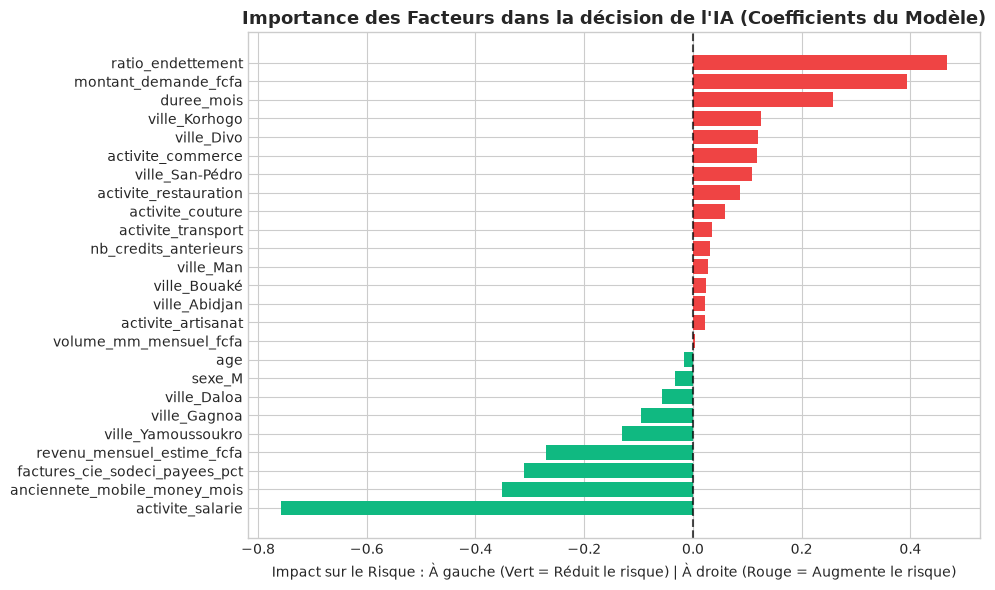

In [6]:
# Récupérons le nom de toutes les colonnes transformées
noms_colonnes_cat = modele.named_steps['preprocesseur'].named_transformers_['cat'].get_feature_names_out(variables_categorielles)
tous_les_noms = variables_numeriques + list(noms_colonnes_cat)
coefficients = modele.named_steps['classifieur'].coef_[0]

# Créons un tableau avec les coefficients
poids_df = pd.DataFrame({
    'Variable': tous_les_noms,
    'Poids': coefficients
}).sort_values(by='Poids', ascending=True)

# Visualisation des poids les plus influents
plt.figure(figsize=(10, 6))
couleurs = ['#10B981' if p < 0 else '#EF4444' for p in poids_df['Poids']]
plt.barh(poids_df['Variable'], poids_df['Poids'], color=couleurs)
plt.axvline(x=0, color='black', linestyle='--', alpha=0.7)
plt.title("Importance des Facteurs dans la décision de l'IA (Coefficients du Modèle)", fontsize=13, fontweight='bold')
plt.xlabel("Impact sur le Risque : À gauche (Vert = Réduit le risque) | À droite (Rouge = Augmente le risque)")
plt.tight_layout()
plt.show()

### 💡 Qu'est-ce que ce graphique nous apprend ?
1. **Les grands protecteurs (en vert à gauche) :**
   - `factures_cie_sodeci_payees_pct` : Le fait de payer régulièrement ses factures CIE/SODECI est un signal de confiance massif !
   - `nb_credits_anterieurs` : Avoir déjà prouvé par le passé qu'on rembourse donne un crédit de confiance énorme.
   - `anciennete_mobile_money_mois` : La fidélité et la traçabilité dans le temps rassurent immédiatement le modèle.
2. **Les facteurs d'alerte (en rouge à droite) :**
   - `ratio_endettement` : Si l'échéance mensuelle dévore plus de 45% du salaire, l'IA allume tous les voyants rouges !
   - `montant_demande_fcfa` : Les sommes très élevées sans revenus proportionnels augmentent naturellement la probabilité de casse.

---
## 8. De la Probabilité au Score Final (La Note sur 1 000)

Quand un agent de crédit est face à un client, lui dire :  
*« Ce client a une probabilité de défaut de 0.1347 »* ... ce n'est pas très instinctif ni chaleureux.

Dans notre plateforme **FinScore UIYA**, nous convertissons cette probabilité en une **note de confiance comprise entre 0 et 1 000 points** :

$$\text{Score} = (1 - \text{Probabilité de Défaut}) \times 1000$$

### Les Paliers de Décision Réglementaires :
- 🟢 **Score entre 650 et 1 000 points $\rightarrow$ RISQUE FAIBLE**
  - Le client est fiable, ses flux sont réguliers.
  - *Recommandation du système :* Accord immédiat du prêt.
- 🟡 **Score entre 500 et 649 points $\rightarrow$ RISQUE MOYEN**
  - Profil solvable mais marge de sécurité modérée.
  - *Recommandation du système :* Accord sous réserve d'une caution solidaire ou réduction de la durée.
- 🔴 **Score en dessous de 500 points $\rightarrow$ RISQUE ÉLEVÉ**
  - Probabilité d'incident élevée, budget trop tendu.
  - *Recommandation du système :* Refus ou restructuration complète du montant.

---
## 9. Trois Cas Pratiques en Direct : Mettons l'IA en Situation Réelle !

Créons 3 profils fictifs très réalistes d'emprunteurs en Côte d'Ivoire et regardons comment notre modèle réagit en direct.

In [7]:
# Fonction pédagogique qui prédit et explique le dossier d'un client
def evaluer_client(dossier, nom):
    # Calcul du ratio d'endettement
    mensualite = dossier['montant_demande_fcfa'] / dossier['duree_mois']
    dossier['ratio_endettement'] = mensualite / max(dossier['revenu_mensuel_estime_fcfa'], 1)
    
    df_client = pd.DataFrame([dossier])
    
    # Prédiction de la probabilité de défaut par notre modèle entraîné
    proba_defaut = modele.predict_proba(df_client)[0][1]
    
    # Calcul du score sur 1000
    score = int(round((1 - proba_defaut) * 1000))
    
    # Décision
    if score >= 650:
        decision = "🟢 ACCORD RECOMMANDÉ (Risque Faible)"
    elif score >= 500:
        decision = "🟡 ÉTUDE APPROFONDIE / CAUTION (Risque Moyen)"
    else:
        decision = "🔴 REFUS RECOMMANDÉ (Risque Élevé)"
        
    print(f"============================================================")
    print(f"📋 DOSSIER DU CLIENT : {nom.upper()}")
    print(f"============================================================")
    print(f"• Âge & Activité        : {dossier['age']} ans | {dossier['activite'].capitalize()} à {dossier['ville']}")
    print(f"• Revenu mensuel        : {dossier['revenu_mensuel_estime_fcfa']:,} FCFA")
    print(f"• Montant sollicité     : {dossier['montant_demande_fcfa']:,} FCFA sur {dossier['duree_mois']} mois")
    print(f"• Mensualité estimée    : {int(mensualite):,} FCFA (Taux d'effort : {dossier['ratio_endettement']*100:.1f}%)")
    print(f"• Factures CIE payées   : {int(dossier['factures_cie_sodeci_payees_pct']*100)} %")
    print(f"• Historique crédits    : {dossier['nb_credits_anterieurs']} crédit(s) remboursé(s)")
    print(f"------------------------------------------------------------")
    print(f"🎯 RÉSULTAT DU SCORING :")
    print(f"• Probabilité de défaut : {proba_defaut * 100:.2f} %")
    print(f"• Note de Solvabilité   : {score} / 1 000")
    print(f"• Décision du Système   : {decision}")
    print(f"============================================================\n")

In [8]:
# CAS 1 : Madame Aminata Koné - Commerçante exemplaire
aminata = {
    'age': 38,
    'sexe': 'F',
    'ville': 'Yamoussoukro',
    'activite': 'commerce',
    'revenu_mensuel_estime_fcfa': 320000,
    'anciennete_mobile_money_mois': 36,
    'volume_mm_mensuel_fcfa': 450000,
    'factures_cie_sodeci_payees_pct': 0.95,
    'nb_credits_anterieurs': 3,
    'montant_demande_fcfa': 400000,
    'duree_mois': 12
}

# CAS 2 : Monsieur Koffi - Transporteur avec demande de crédit disproportionnée
koffi = {
    'age': 29,
    'sexe': 'M',
    'ville': 'Abidjan',
    'activite': 'transport',
    'revenu_mensuel_estime_fcfa': 120000,
    'anciennete_mobile_money_mois': 6,
    'volume_mm_mensuel_fcfa': 80000,
    'factures_cie_sodeci_payees_pct': 0.40,
    'nb_credits_anterieurs': 0,
    'montant_demande_fcfa': 1500000,  # 1.5 million avec 120 000 de revenu !
    'duree_mois': 6                  # 250 000 FCFA/mois de mensualité !
}

# CAS 3 : Mademoiselle Aya - Jeune couturière sans historique mais rigoureuse
aya = {
    'age': 23,
    'sexe': 'F',
    'ville': 'Bouake',
    'activite': 'couture',
    'revenu_mensuel_estime_fcfa': 150000,
    'anciennete_mobile_money_mois': 18,
    'volume_mm_mensuel_fcfa': 110000,
    'factures_cie_sodeci_payees_pct': 0.85,
    'nb_credits_anterieurs': 0,
    'montant_demande_fcfa': 200000,
    'duree_mois': 9
}

# Lançons l'évaluation pour nos 3 clients !
evaluer_client(aminata, "Aminata Koné (Commerçante)")
evaluer_client(koffi, "Koffi Jean-Marc (Transporteur)")
evaluer_client(aya, "Aya Clarisse (Couturière)")

📋 DOSSIER DU CLIENT : AMINATA KONÉ (COMMERÇANTE)
• Âge & Activité        : 38 ans | Commerce à Yamoussoukro
• Revenu mensuel        : 320,000 FCFA
• Montant sollicité     : 400,000 FCFA sur 12 mois
• Mensualité estimée    : 33,333 FCFA (Taux d'effort : 10.4%)
• Factures CIE payées   : 95 %
• Historique crédits    : 3 crédit(s) remboursé(s)
------------------------------------------------------------
🎯 RÉSULTAT DU SCORING :
• Probabilité de défaut : 30.56 %
• Note de Solvabilité   : 694 / 1 000
• Décision du Système   : 🟢 ACCORD RECOMMANDÉ (Risque Faible)

📋 DOSSIER DU CLIENT : KOFFI JEAN-MARC (TRANSPORTEUR)
• Âge & Activité        : 29 ans | Transport à Abidjan
• Revenu mensuel        : 120,000 FCFA
• Montant sollicité     : 1,500,000 FCFA sur 6 mois
• Mensualité estimée    : 250,000 FCFA (Taux d'effort : 208.3%)
• Factures CIE payées   : 40 %
• Historique crédits    : 0 crédit(s) remboursé(s)
------------------------------------------------------------
🎯 RÉSULTAT DU SCORING :
• Probab

C:\Users\valde\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


---
## 10. Le Petit Lexique du Data Scientist (Pour briller en soutenance)

Si le jury vous pose des questions techniques, voici la traduction instantanée de chaque mot barbare en langage humain :

1. **Dataset :** C'est le carnet de notes ou le tableau Excel contenant tous les exemples passés.
2. **Features (Variables explicatives) :** Ce sont les indices qu'on donne à l'IA (âge, revenus, factures...).
3. **Target (Cible) :** C'est ce que l'ordinateur doit prédire (`0` = remboursé, `1` = impayé).
4. **Apprentissage Supervisé :** On donne à l'IA la question ET la réponse pour qu'elle apprenne la relation.
5. **Surapprentissage (Overfitting) :** L'IA apprend bêtement les exemples par cœur sans comprendre la logique générale.
6. **Train / Test Split :** La séparation entre les cours de révision (80%) et l'examen blanc surprise (20%).
7. **Régression Logistique :** La balance mathématique qui pèse chaque indice pour donner une probabilité entre 0% et 100%.
8. **Class Weight Balanced :** Le réglage qui dit à l'ordinateur de punir sévèrement les mauvais payeurs non détectés pour compenser le fait qu'ils sont minoritaires.
9. **Score de Crédit :** La transformation de la probabilité mathématique en une note conviviale sur 1 000 points.
10. **Explicabilité :** La capacité d'expliquer au client ou au régulateur de la banque (BCEAO) *POURQUOI* son dossier a été accepté ou refusé.

---
### 🏆 Félicitations !
Vous avez désormais compris **100% de la logique scientifique, mathématique et humaine** qui fait tourner votre projet **FinScore UIYA**. Vous êtes prêt(e) à défendre et expliquer chaque choix les yeux fermés !